# Proyecto Equipo A: análisis del panorama musical actual
## Introducción
En este proyecto nos hemos propuesto realizar análisis del panorama musical actual a partir de datos extraídos de dos fuentes principales: **Billboard**, que ofrece información sobre el rendimiento de las canciones en las listas de éxitos, y **Spotify**, que proporciona métricas detalladas sobre las características de las canciones y los hábitos de consumo de los oyentes.

El objetivo principal de este análisis es identificar patrones y correlaciones entre diversos parámetros de las canciones, como géneros musicales, popularidad, características acústicas y posiciones en las listas de éxitos. Además, se busca comprender cuáles son los géneros y canciones más populares en diferentes períodos, observar cómo evolucionan las tendencias musicales a lo largo del tiempo y descubrir posibles factores que influyen en el éxito de una canción.

A través de técnicas de visualización y análisis de datos, este proyecto busca no solo responder preguntas sobre el comportamiento de las canciones en el mercado musical, sino también ofrecer herramientas para anticipar tendencias y enriquecer la comprensión de la industria musical moderna.

## Metodología
El proyecto tiene varias fases en las que se irá desarrollando:
1. **Extraction.**
Para llevar el análisis a cabo, vamos a utilizar dos métodos para **extraer datos** de diversas fuentes:
    + **Webscraping.** Crearemos un código para extraer los datos de la lista *Billboard Hot 100* del último año (desde noviembre de 2023 hasta noviembre de 2024). Esta lista recopila datos de diversas fuentes y plataformas para medir el éxito comerciales de las canciones: https://www.billboard.com/charts/hot-100/
    + **API de Spotify.** Nos serviremos también de la API de Spotify para sacar datos asociados a las canciones que aparecen en la lista *Billboard*. Esta API aporta parámetros interesantes asociados a cada título, así como el género y número de seguidores ded cada artista.
    
2. **Transform.**
Una vez obtenidos los datos, habrá que formatearlos y limpiarlos para poder utilizarlos. Veremos cómo gestionar los valores nulos, eliminar columnas innecesarias, dar el formato adecuado a los datos y añadir columnas que puedan ser interesantes.

3. **Load.**
Cargaremos los datos en *Airtable* para tenerlos guardados en una base de datos.

4. **Visualization.**
Haremos diferentes visualizaciones para una observación más clara de los datos y extraer *insights* y conclusiones. También se hará un contraste de hipótesis para apoyar la visualización de datos.

5. **Storytelling.**
Conclusiones extraídas tras el análisis de los datos.

A partir de aquí, importaremos las librerías necesarias y comenzaremos el proceso.

In [ ]:
import pandas as pd
import numpy as np
import time
import passwords

from bs4 import BeautifulSoup
import requests

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from datetime import datetime, timedelta
from time import sleep
import random

import spotipy
from spotipy.oauth2 import SpotifyClientCredentials
from spotipy.oauth2 import SpotifyOAuth

from pprint import pprint

## 1. Extraction and 2. Transform

Preparamos los datos necesarios para hacer la request a la web de Billboard y extraer los datos desde noviembre de 2023 hasta hoy. Simplemente, tendremos que añadir como endpoint la fecha a la que queramos acceder para ver la lista en dicho momento.

In [2]:
base_url = "https://www.billboard.com/charts/hot-100/"

# con esto, haremos creer a la web web que no estamos haciendo peticiones masivas y saltarnos el bloqueo
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/114.0.0.0 Safari/537.36',
    'Accept-Language': 'en-US,en;q=0.9',
}

# declaramos las fechas de inicio y fin de la extracción de datos.
start_date = datetime(2023, 11, 16)
end_date = datetime(2024, 11, 16)

# metemos en una lista las fechas que usaremos como endpoint para acceder a los datos
dates = []
current_date = start_date
while current_date <= end_date:
    dates.append(current_date.strftime('%Y-%m-%d'))
    current_date += timedelta(weeks=1)

print(dates)

['2023-11-16', '2023-11-23', '2023-11-30', '2023-12-07', '2023-12-14', '2023-12-21', '2023-12-28', '2024-01-04', '2024-01-11', '2024-01-18', '2024-01-25', '2024-02-01', '2024-02-08', '2024-02-15', '2024-02-22', '2024-02-29', '2024-03-07', '2024-03-14', '2024-03-21', '2024-03-28', '2024-04-04', '2024-04-11', '2024-04-18', '2024-04-25', '2024-05-02', '2024-05-09', '2024-05-16', '2024-05-23', '2024-05-30', '2024-06-06', '2024-06-13', '2024-06-20', '2024-06-27', '2024-07-04', '2024-07-11', '2024-07-18', '2024-07-25', '2024-08-01', '2024-08-08', '2024-08-15', '2024-08-22', '2024-08-29', '2024-09-05', '2024-09-12', '2024-09-19', '2024-09-26', '2024-10-03', '2024-10-10', '2024-10-17', '2024-10-24', '2024-10-31', '2024-11-07', '2024-11-14']


Esta es la función principal para parsear la web. Tomará la URL base, los headers y la lista con las fechas.

In [ ]:
def get_info(url, user_headers, user_date):
    "Obtiene los datos de una lista para la semana de la fecha indicada y lo devuelve en un dataframe"

    # respuesta y objeto BS
    response = requests.get(url, headers=user_headers)
    soup = BeautifulSoup(response.text, "html.parser")

    # listas de las que extraeremos los datos
    # la mayoría los extraemos del mismo objeto soup_elements
    # la posición en la lista y la imagen de la canción debemos extraerla de otros diferentes
    soup_elements = soup.find_all("ul", class_="lrv-a-unstyle-list lrv-u-flex lrv-u-height-100p lrv-u-flex-direction-column@mobile-max")
    soup_position = soup.find_all("li", class_="o-chart-results-list__item // lrv-u-background-color-black lrv-u-color-white u-width-100 u-width-55@mobile-max u-width-55@tablet-only lrv-u-height-100p lrv-u-flex lrv-u-flex-direction-column lrv-u-flex-shrink-0 lrv-u-align-items-center lrv-u-justify-content-center lrv-u-border-b-1 u-border-b-0@mobile-max lrv-u-border-color-grey")
    soup_image = soup.find_all("div", class_="lrv-a-crop-1x1 a-crop-67x100@mobile-max")

    # declaramos las listas vacías donde guardaremoslos datos
    titles = []
    artists = []
    this_week = []
    last_week = []
    peaks = []
    wks_on_chart = []
    images = []
    

    for elem in soup_position:
    # posición actual en la fecha dada
        try:
            this_week.append(elem.find("span").text.replace("\n","").replace("\t",""))
                                                        
        except:
            this_week.append(np.nan)

    for elem in soup_elements:

    # títulos de las canciones
        try:
            titles.append(elem.find("h3", id="title-of-a-story").text.replace("\n","").replace("\t",""))
        except:
            titles.append(np.nan)
    #-----------------------------------------------------------------------------------------------------------------------------------------------
    # artistas
    for elem in soup_elements:
        try:
            artists.append(elem.find("span",).text.replace("\n","").replace("\t",""))
        except:
            artists.append(np.nan)
    #-----------------------------------------------------------------------------------------------------------------------------------------------
    
    #-----------------------------------------------------------------------------------------------------------------------------------------------
    # posición de la semana anterior
        try:
            last_week.append(elem.find_all("li")[3].text.replace("\n","").replace("\t",""))                  
        except:
            last_week.append(np.nan)
    #-----------------------------------------------------------------------------------------------------------------------------------------------
    # posición más alta
        try:
            peaks.append(elem.find_all("li")[4].text.replace("\n","").replace("\t",""))                  
        except:
            peaks.append(np.nan)
    #-----------------------------------------------------------------------------------------------------------------------------------------------
    # semanas en lista
        try:
            wks_on_chart.append(elem.find_all("li")[5].text.replace("\n","").replace("\t",""))                  
        except:
            wks_on_chart.append(np.nan)
    #-----------------------------------------------------------------------------------------------------------------------------------------------
    # imagen
    for elem in soup_image:
        try:
            images.append(elem.find("img")["src"])
        except:
            images.append(np.nan)
    #-----------------------------------------------------------------------------------------------------------------------------------------------
    # fecha de la semana
    week = [user_date for i in range(100)]

    #print(len(titles), len(artists), len(this_week), len(last_week), len(peaks), len(wks_on_chart))   

    # sleep
    sleep(random.uniform(0.5, 2.5))
    
    # guardamos en un df
    df_data = pd.DataFrame({"Title" : titles,
                 "Artist" : artists, 
                 "Pos. this week" : this_week, 
                 "Pos. last week" : last_week, 
                 "Peak position" : peaks, 
                 "Weeks on chart" : wks_on_chart,
                 "Image" : images,
                 "Date" : week})
    
    # print(response.status_code)
    
    return df_data
    
    

Declaramos un dataframe vacío donde guardaremos todos los datos, los cuales vamos concatenando, semana a semana. Luego lo guardamos en un csv.

In [ ]:
df = pd.DataFrame(columns=["Title", "Artist", "Pos. this week", "Pos. last week", "Peak position", "Weeks on chart", "Image", "Date"])
for date in dates:
    df = pd.concat([df, get_info(f"{base_url}{date}/", headers, date)], ignore_index=True)

In [ ]:
df.to_csv("billboard100.csv", index=False)

In [2]:
df = pd.read_csv('billboard100.csv')
df

,Title,Artist,Pos. this week,Pos. last week,Peak position,Weeks on chart,Image,Date
0,Cruel Summer,Taylor Swift,1,1,1,28,https://charts-static.billboard.com/img/2019/0...,2023-11-21
1,Lovin On Me,Jack Harlow,2,-,2,1,https://charts-static.billboard.com/img/2023/1...,2023-11-21
2,Paint The Town Red,Doja Cat,3,2,1,15,https://charts-static.billboard.com/img/2023/0...,2023-11-21
3,Snooze,SZA,4,4,2,49,https://charts-static.billboard.com/img/2022/1...,2023-11-21
4,Is It Over Now? (Taylor's Version) [From The V...,Taylor Swift,5,3,1,3,https://charts-static.billboard.com/img/2006/0...,2023-11-21
...,...,...,...,...,...,...,...,...
5295,Prove It,21 Savage & Summer Walker,96,92,43,19,https://charts-static.billboard.com/img/2016/0...,2024-11-19
5296,4x4xU,Lainey Wilson,97,-,97,1,https://charts-static.billboard.com/img/2024/0...,2024-11-19
5297,I Ain't Sayin',Jordan Davis,98,-,98,1,https://charts-static.billboard.com/img/2024/0...,2024-11-19
5298,The Largest,BigXthaPlug,99,-,99,1,https://charts-static.billboard.com/img/2024/1...,2024-11-19


Para usar la API de Spotify, necesitamos registrarnos y crear una aplicación en en la web. Esto nos dará unas credenciales para poder acceder a los datos.

In [ ]:
# Replace with your Spotify API credentials
client_id = passwords.id
client_secret = passwords.secret

# Authenticate using Client Credentials Flow
client_credentials_manager = SpotifyClientCredentials(client_id=client_id, client_secret=client_secret)
sp = spotipy.Spotify(client_credentials_manager=client_credentials_manager)

print("Authentication successful!")

Podemos hacer una prueba para ver una canción individual. Para ello, declaramos una función que podamos utilizar en cualquier momento.

In [401]:
# # Search for a track by name
# track_name = "Jingle Bells"
# artist_name = "Frank Sinatra"

def song_data(track_name, artist_name):
    query = f"track:{track_name} artist:{artist_name}"
    results = sp.search(q=query, type="track", limit=1)

    # Extract and print track details
    for track in results['tracks']['items']:
        print(f"Track Name: {track['name']}")
        print(f"Artist: {track['artists'][0]['name']}")
        print(f"Album: {track['album']['name']}")
        print(f"Release date: {track['album']['release_date']}")
        print(f"Popularity: {track['popularity']}")
        print(f"Spotify URL: {track['external_urls']['spotify']}")
        print(f"Song ID: {track['id']}")
        artist_id = track['artists'][0]['id']
        print(f"Artist ID: {artist_id}")
        artist_info = sp.artist(artist_id)
        print(f"Genres: {artist_info['genres']}")
        print(f"Followers: {artist_info['followers']['total']}")

    return


In [402]:
song_data("Jingle Bells", "Frank Sinatra")

Track Name: Jingle Bells - Remastered 1999
Artist: Frank Sinatra
Album: A Jolly Christmas From Frank Sinatra
Release date: 1957-09
Popularity: 71
Spotify URL: https://open.spotify.com/track/4HEOgBHRCExyYVeTyrXsnL
Song ID: 4HEOgBHRCExyYVeTyrXsnL
Artist ID: 1Mxqyy3pSjf8kZZL4QVxS0
Genres: ['adult standards', 'easy listening', 'lounge']
Followers: 7591282


Crearemos un dataframe con los títulos y artistas únicos que podemos encontrar en la lista Billboard para extraer los datos de cada una con la API de Spotify.

In [415]:
songlist = []
artistlist = []
# track_ids = []
for song,artist in zip(df["Title"], df["Artist"]):
    if song not in songlist:
        songlist.append(song)
        artistlist.append(artist)

    else:
        pass

In [416]:
df_metadata = pd.DataFrame()
df_metadata["Title"] = songlist
df_metadata["Artist"] = artistlist

In [ ]:
df_metadata.to_csv("df_metadata.csv", index=False)

La función principal para recoger datos va cogiendo canciones por lotes, ya que la API tiene sus limitaciones. Además, lotes muy grandes, aunque estén dentro del límite de 100, pueden llegar a dar errores.

Aquí, hemos tenido problemas usando el método <b>sp.artist</b>, necesario para obtener los géneros asociados a cada artista, así como el número de seguidores. Durante esta semana, dejó de fucionar y nos ha sido imposible extraer esos datos.

In [420]:
def fetch_tracks_in_batches(df, sp, batch_size=50):
    """
    Extracción de datos con la API de Spotify por lotes
    Args:
        df (DataFrame): DataFrame con las canciones y artistas que buscaremos.
        sp (Spotify): autenticación.
        batch_size (int): número de canciones que se procesan a la vez.
    Retorna:
        DataFrame con los datos de cada canción.
    """
    all_metadata = []

    for i in range(0, len(df), batch_size):
        batch = df.iloc[i:i + batch_size]
        print(f"Processing batch {i // batch_size + 1}...")

        for _, row in batch.iterrows():
            try:
                
                # Limpieza del formato de los nombres de los artistas para aumentar las probabilidades de matching
                temp_title = row['Title'].replace('The ', "").replace("We ","")   # esto lo hacemos porque si no aparecen duplicados
                temp_artist = row['Artist'].replace("& ", "").replace("And ", "").replace("Featuring ", "").replace("¥$: ", "")
                query = f"track:{temp_title} artist:{temp_artist}"
                results = sp.search(q=query, type="track", limit=1)
                # print(f"data found: {results}")
                # print(f"tracks,items: {results['tracks']['items']}")
                if results['tracks']['items']:

                    track = results['tracks']['items'][0]

                    # print(f"tracks,items,0: {results['tracks']['items'][0]}")

                    # ID del artista para extraer género. 
                    artist_id = [artist['id'] for artist in track['artists']][0]
                    # print(f"artist id: {artist_id}")
                    artist_info = sp.artist(artist_id)
                    # print(f"finding: {artist_id}, {artist_info}")

                    # Extracción de metadatos
                    all_metadata.append({
                        "track_name": row['Title'],
                        "artist_name": row['Artist'],
                        "album_name": track["album"]["name"],
                        "track_id": track['id'],
                        "artist_id": artist_id,
                        "popularity": track['popularity'],
                        "release_date": track['album']['release_date'],
                        "spotify_url": track['external_urls']['spotify'],
                        "genres": artist_info["genres"],  # Get genres
                        "followers": artist_info['followers']['total']  # Get artist followers
                    })
                    # print("data appended")
                else:
                    all_metadata.append({
                        "track_name": row['Title'],
                        "artist_name": row['Artist'],
                        "album_name": None,
                        "track_id": None,
                        "artist_id": None,
                        "popularity": None,
                        "release_date": None,
                        "spotify_url": None,
                        "genres": None,
                        "followers": None
                    })
                    # print("Nones appended")
            except Exception as e:
                print(f"Error processing track {row['Title']} by {row['Artist']}: {e}")
                all_metadata.append({
                    "track_name": row['Title'],
                    "artist_name": row['Artist'],
                    "album_name": None,
                    "track_id": None,
                    "artist_id": None,
                    "popularity": None,
                    "release_date": None,
                    "spotify_url": None,
                    "genres": None,
                    "followers": None
                })
        # Delay
        sleep(random.uniform(0.5, 1.5))
        

    # Retorna un df
    return pd.DataFrame(all_metadata)


Usamos la función y concatenamos los datos en un nuevo df llamado **df_metadata**.

In [418]:
df_tracks = fetch_tracks_in_batches(df_metadata, sp)
df_metadata = pd.concat([df_metadata, df_tracks], axis=1)

Processing batch 1...
Processing batch 2...
Processing batch 3...
Processing batch 4...
Processing batch 5...
Processing batch 6...
Processing batch 7...
Processing batch 8...
Processing batch 9...
Processing batch 10...
Processing batch 11...
Processing batch 12...
Processing batch 13...
Processing batch 14...
Processing batch 15...
Processing batch 16...
Processing batch 17...
Processing batch 18...
Processing batch 19...


In [419]:
df_metadata

,Title,Artist,track_name,artist_name,album_name,track_id,artist_id,popularity,release_date,spotify_url,genres,followers
0,Cruel Summer,Taylor Swift,Cruel Summer,Taylor Swift,Lover,1BxfuPKGuaTgP7aM0Bbdwr,06HL4z0CvFAxyc27GXpf02,89.0,2019-08-23,https://open.spotify.com/track/1BxfuPKGuaTgP7a...,[pop],126410681.0
1,Paint The Town Red,Doja Cat,Paint The Town Red,Doja Cat,Paint The Town Red,2IGMVunIBsBLtEQyoI1Mu7,5cj0lLjcoR7YOSnhnX0Po5,78.0,2023-08-04,https://open.spotify.com/track/2IGMVunIBsBLtEQ...,"[dance pop, pop]",31900940.0
2,Is It Over Now? (Taylor's Version) [From The V...,Taylor Swift,Is It Over Now? (Taylor's Version) [From The V...,Taylor Swift,1989 (Taylor's Version),1Iq8oo9XkmmvCQiGOfORiz,06HL4z0CvFAxyc27GXpf02,75.0,2023-10-26,https://open.spotify.com/track/1Iq8oo9XkmmvCQi...,[pop],126410681.0
3,Snooze,SZA,Snooze,SZA,SOS,4iZ4pt7kvcaH6Yo8UoZ4s2,7tYKF4w9nC0nq9CsPZTHyP,86.0,2022-12-09,https://open.spotify.com/track/4iZ4pt7kvcaH6Yo...,"[pop, r&b, rap]",24431271.0
4,Standing Next To You,Jung Kook,Standing Next To You,Jung Kook,GOLDEN,2KslE17cAJNHTsI2MI0jb2,6HaGTQPmzraVmaVxvz6EUc,89.0,2023-11-03,https://open.spotify.com/track/2KslE17cAJNHTsI...,[k-pop],16483609.0
...,...,...,...,...,...,...,...,...,...,...,...,...
755,Chill Bae,Lil Uzi Vert,Chill Bae,Lil Uzi Vert,Eternal Atake 2,4ppKM7xnkSAwSyKqD4QTY4,4O15NlyKLIASxsJ0PrXPfz,76.0,2024-11-01,https://open.spotify.com/track/4ppKM7xnkSAwSyK...,"[hip hop, melodic rap, philly rap, rage rap, r...",18043364.0
756,Light Year (Practice),Lil Uzi Vert,Light Year (Practice),Lil Uzi Vert,Eternal Atake 2,3NE6g9h77FZbQqCLzUpGRt,4O15NlyKLIASxsJ0PrXPfz,73.0,2024-11-01,https://open.spotify.com/track/3NE6g9h77FZbQqC...,"[hip hop, melodic rap, philly rap, rage rap, r...",18043364.0
757,Sao Paulo,The Weeknd & Anitta,Sao Paulo,The Weeknd & Anitta,São Paulo,0xGQTpN4ESETtl1Sp6rzd2,1Xyo4u8uXC1ZmMpatF05PJ,86.0,2024-10-31,https://open.spotify.com/track/0xGQTpN4ESETtl1...,"[canadian contemporary r&b, canadian pop, pop]",94767820.0
758,We Good,Lil Uzi Vert,We Good,Lil Uzi Vert,Eternal Atake 2,0F60WLPs6Oz2slHomvLt9U,4O15NlyKLIASxsJ0PrXPfz,70.0,2024-11-01,https://open.spotify.com/track/0F60WLPs6Oz2slH...,"[hip hop, melodic rap, philly rap, rage rap, r...",18043364.0


Iremos guardando cada dataset en varios checkpoint, por seguridad.

In [421]:
df_metadata.to_csv('dataset_1.csv', index=False)

Con esta segunda función, recogemos los parámetros asociados a cada canción, tales como la duración, la bailabilidad, el tempo, etc. Esta necesita el id de cada canción para acceder a ellos.

In [422]:
def fetch_audio_features_in_batches(track_ids, sp, batch_size=40):
    """
    Extraer los parámetros de cada canción.
    Args:
        track_ids (list): Lista con los IDs de las canciones.
        sp (Spotify): Autenticación.
        batch_size (int): número de canciones que se procesan a la vez.
    Retorna:
        lista: con los parámetros de las canciones
    """
    # lista vacía ddonde se guardarán los parámetros
    all_features = []
    
    # Dividir en lotes
    for i in range(0, len(track_ids), batch_size):
        batch = track_ids[i:i + batch_size] 
        
        try:
            # Extraer la info para el batch actual
            features = sp.audio_features(batch)
            
            # Guardar la info en la lista all_features
            if features:
                all_features.extend(features)
            
            # Delay
            time.sleep(random.uniform(0.5, 1.5)) 
            
        except Exception as e:
            print(f"Error fetching batch {i // batch_size + 1}: {e}")
            continue  
    
    return all_features


In [423]:
# IDs de las canciones
track_ids = df_metadata['track_id'].dropna().tolist()  # Eliminamos los Nan

# Extraer los datos
audio_features = fetch_audio_features_in_batches(track_ids, sp)

# Pasamos a df
df_audio_features = pd.DataFrame(audio_features)

# Renombramos la columna de 'id' que nos devuelve, ya que es la misma que 'track_id que tenemos
df_audio_features.rename(columns={'id': 'track_id'}, inplace=True)

# Unimos los dataframe, asegurando que coinciden los datos con los de su canción correspondiente
df_metadata = pd.merge(df_metadata, df_audio_features, on='track_id', how='left')

# Reset index
df_metadata.reset_index(drop=True, inplace=True)


Ahora, iremos haciendo análisis del dataframe para comprobar el estado de los datos.

In [424]:
pd.DataFrame(track_ids).duplicated().sum()

np.int64(1)

In [425]:
df_metadata.shape

(762, 29)

In [426]:
df_metadata.to_csv("dataset_2.csv", index=False)

In [ ]:
#df_metadata = pd.read_csv("metadata.csv")
df_metadata.columns

Index(['Title', 'Artist', 'track_name', 'artist_name', 'album_name',
       'track_id', 'artist_id', 'popularity', 'release_date', 'spotify_url',
       'genres', 'followers', 'danceability', 'energy', 'key', 'loudness',
       'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness',
       'valence', 'tempo', 'type', 'uri', 'track_href', 'analysis_url',
       'duration_ms', 'time_signature'],
      dtype='object')

In [20]:
df_metadata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 762 entries, 0 to 761
Data columns (total 29 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Title             762 non-null    object 
 1   Artist            762 non-null    object 
 2   track_name        762 non-null    object 
 3   artist_name       762 non-null    object 
 4   album_name        743 non-null    object 
 5   track_id          743 non-null    object 
 6   artist_id         743 non-null    object 
 7   popularity        743 non-null    float64
 8   release_date      743 non-null    object 
 9   spotify_url       743 non-null    object 
 10  genres            743 non-null    object 
 11  followers         743 non-null    float64
 12  danceability      743 non-null    float64
 13  energy            743 non-null    float64
 14  key               743 non-null    float64
 15  loudness          743 non-null    float64
 16  mode              743 non-null    float64
 1

In [ ]:
df_metadata[df_metadata.isna().any(axis=1)]

In [ ]:
df_nan = df_metadata[df_metadata.isna().any(axis=1)]
df_nan = df_nan[df_nan["track_id"].notna()]

In [ ]:
pd.set_option("display.max_columns", None)   # para ver todas las columnas del df en el display

Nos quedamos con las columnas que nos pueden resultar de interés.

In [431]:
df_metadata = df_metadata[['Title', 'Artist', 'album_name',
       'track_id', 'artist_id', 'popularity', 'release_date',
       'genres', 'followers', 'danceability', 'energy', 'key', 'loudness',
       'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness',
       'valence', 'tempo', 'duration_ms']]

In [432]:
df_metadata.tail()

,Title,Artist,album_name,track_id,artist_id,popularity,release_date,genres,followers,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
757,Chill Bae,Lil Uzi Vert,Eternal Atake 2,4ppKM7xnkSAwSyKqD4QTY4,4O15NlyKLIASxsJ0PrXPfz,76.0,2024-11-01,"[hip hop, melodic rap, philly rap, rage rap, r...",18043364.0,0.672,0.663,3.0,-5.984,1.0,0.2430,0.1120,0.0000,0.1340,0.381,184.057,138324.0
758,Light Year (Practice),Lil Uzi Vert,Eternal Atake 2,3NE6g9h77FZbQqCLzUpGRt,4O15NlyKLIASxsJ0PrXPfz,73.0,2024-11-01,"[hip hop, melodic rap, philly rap, rage rap, r...",18043364.0,0.637,0.692,1.0,-7.231,0.0,0.1640,0.0153,0.0000,0.3450,0.427,140.203,164366.0
759,Sao Paulo,The Weeknd & Anitta,São Paulo,0xGQTpN4ESETtl1Sp6rzd2,1Xyo4u8uXC1ZmMpatF05PJ,86.0,2024-10-31,"[canadian contemporary r&b, canadian pop, pop]",94767820.0,0.574,0.659,5.0,-7.377,0.0,0.0768,0.0412,0.0002,0.0921,0.506,127.347,301623.0
760,We Good,Lil Uzi Vert,Eternal Atake 2,0F60WLPs6Oz2slHomvLt9U,4O15NlyKLIASxsJ0PrXPfz,70.0,2024-11-01,"[hip hop, melodic rap, philly rap, rage rap, r...",18043364.0,0.587,0.800,11.0,-3.194,1.0,0.2430,0.0461,0.0000,0.3440,0.823,144.332,125000.0
761,Brokey,Latto,Sugar Honey Iced Tea,1JF8LkQWZ8grXb2emqrNKn,3MdXrJWsbVzdn6fe5JYkSQ,70.0,2024-08-09,[trap queen],1825484.0,0.776,0.525,1.0,-6.723,1.0,0.1370,0.0366,0.0000,0.1080,0.467,75.013,217613.0


Vamos a introducir manualmente alguna de las canciones de las cuales no tenemos los datos. La búsqueda con la API no siempre encuentra bien las canciones. También depende del formato del título y del artista, así como del país desde donde se busque.

In [433]:
df_metadata[df_metadata["Title"] == "Jingle Bells"]

,Title,Artist,album_name,track_id,artist_id,popularity,release_date,genres,followers,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
136,Jingle Bells,Frank Sinatra With The Orchestra & Chorus Of G...,None,None,None,NaN,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [434]:
# Search for a track by name
track_name = "Jingle Bells"
artist_name = "Frank Sinatra"
query = f"track:{track_name} artist:{artist_name}"
results = sp.search(q=query, type="track", limit=1)

# Extract and print track details
for track in results['tracks']['items']:
    print(f"Track Name: {track['name']}")
    print(f"Artist: {track['artists'][0]['name']}")
    print(f"Album: {track['album']['name']}")
    print(f"Release date: {track['album']['release_date']}")
    print(f"Popularity: {track['popularity']}")
    print(f"Spotify URL: {track['external_urls']['spotify']}")
    print(f"Song ID: {track['id']}")
    artist_id = track['artists'][0]['id']
    print(f"Artist ID: {artist_id}")
    artist_info = sp.artist(artist_id)
    print(f"Genres: {artist_info['genres']}")
    print(f"Followers: {artist_info['followers']['total']}")

Track Name: Jingle Bells - Remastered 1999
Artist: Frank Sinatra
Album: A Jolly Christmas From Frank Sinatra
Release date: 1957-09
Popularity: 71
Spotify URL: https://open.spotify.com/track/4HEOgBHRCExyYVeTyrXsnL
Song ID: 4HEOgBHRCExyYVeTyrXsnL
Artist ID: 1Mxqyy3pSjf8kZZL4QVxS0
Genres: ['adult standards', 'easy listening', 'lounge']
Followers: 7591282


In [435]:
vals1 = ['Jingle Bells', 'Frank Sinatra', 'A Jolly Christmas From Frank Sinatra','4HEOgBHRCExyYVeTyrXsnL','1Mxqyy3pSjf8kZZL4QVxS0', 70., '1957-09', [['adult standards', 'easy listening', 'lounge']], 7591282.]
cols1=['Title', 'Artist', 'album_name','track_id', 'artist_id', 'popularity', 'release_date', 'genres', 'followers']
df_sinatra1 = pd.DataFrame(dict(zip(cols1, vals1)))
df_sinatra1

,Title,Artist,album_name,track_id,artist_id,popularity,release_date,genres,followers
0,Jingle Bells,Frank Sinatra,A Jolly Christmas From Frank Sinatra,4HEOgBHRCExyYVeTyrXsnL,1Mxqyy3pSjf8kZZL4QVxS0,70.0,1957-09,"[adult standards, easy listening, lounge]",7591282.0


In [436]:
sinatra = fetch_audio_features_in_batches('4HEOgBHRCExyYVeTyrXsnL',sp)

In [437]:
df_sinatra2 = pd.DataFrame(sinatra)
df_sinatra2

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,type,id,uri,track_href,analysis_url,duration_ms,time_signature
0,0.511,0.34,8,-13.119,1,0.049,0.727,0,0.0977,0.952,174.661,audio_features,4HEOgBHRCExyYVeTyrXsnL,spotify:track:4HEOgBHRCExyYVeTyrXsnL,https://api.spotify.com/v1/tracks/4HEOgBHRCExy...,https://api.spotify.com/v1/audio-analysis/4HEO...,120693,4


In [438]:
df_sinatra = pd.merge(df_sinatra1, df_sinatra2, left_on='track_id', right_on= 'id')

In [439]:
df_sinatra = df_sinatra[[ 'Title', 'Artist',
       'album_name', 'track_id', 'artist_id','popularity', 'release_date',
       'genres', 'followers', 'danceability', 'energy', 'key', 'loudness',
       'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness',
       'valence', 'tempo', 'duration_ms']]

In [440]:
df_sinatra

,Title,Artist,album_name,track_id,artist_id,popularity,release_date,genres,followers,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,Jingle Bells,Frank Sinatra,A Jolly Christmas From Frank Sinatra,4HEOgBHRCExyYVeTyrXsnL,1Mxqyy3pSjf8kZZL4QVxS0,70.0,1957-09,"[adult standards, easy listening, lounge]",7591282.0,0.511,0.34,8,-13.119,1,0.049,0.727,0,0.0977,0.952,174.661,120693


In [441]:
df_sinatra.shape

(1, 21)

In [442]:
df_metadata = pd.concat([df_metadata, df_sinatra], ignore_index=True)

Sinatra añadido.

In [451]:
df_metadata.tail()

,Title,Artist,album_name,track_id,artist_id,popularity,release_date,genres,followers,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_sec,duration_min
758,Light Year (Practice),Lil Uzi Vert,Eternal Atake 2,3NE6g9h77FZbQqCLzUpGRt,4O15NlyKLIASxsJ0PrXPfz,73.0,2024-11-01,"[hip hop, melodic rap, philly rap, rage rap, r...",18043364.0,0.637,0.692,1.0,-7.231,0.0,0.1640,0.0153,0.0000,0.3450,0.427,140.203,164.4,2.74
759,Sao Paulo,The Weeknd & Anitta,São Paulo,0xGQTpN4ESETtl1Sp6rzd2,1Xyo4u8uXC1ZmMpatF05PJ,86.0,2024-10-31,"[canadian contemporary r&b, canadian pop, pop]",94767820.0,0.574,0.659,5.0,-7.377,0.0,0.0768,0.0412,0.0002,0.0921,0.506,127.347,301.6,5.03
760,We Good,Lil Uzi Vert,Eternal Atake 2,0F60WLPs6Oz2slHomvLt9U,4O15NlyKLIASxsJ0PrXPfz,70.0,2024-11-01,"[hip hop, melodic rap, philly rap, rage rap, r...",18043364.0,0.587,0.800,11.0,-3.194,1.0,0.2430,0.0461,0.0000,0.3440,0.823,144.332,125.0,2.08
761,Brokey,Latto,Sugar Honey Iced Tea,1JF8LkQWZ8grXb2emqrNKn,3MdXrJWsbVzdn6fe5JYkSQ,70.0,2024-08-09,[trap queen],1825484.0,0.776,0.525,1.0,-6.723,1.0,0.1370,0.0366,0.0000,0.1080,0.467,75.013,217.6,3.63
762,Jingle Bells,Frank Sinatra,A Jolly Christmas From Frank Sinatra,4HEOgBHRCExyYVeTyrXsnL,1Mxqyy3pSjf8kZZL4QVxS0,70.0,1957-09,"[adult standards, easy listening, lounge]",7591282.0,0.511,0.340,8.0,-13.119,1.0,0.0490,0.7270,0.0000,0.0977,0.952,174.661,120.7,2.01


Vamos a añadir la duración de las canciones en segundos y en minutos.

In [ ]:
df_metadata["duration_ms"] = df_metadata["duration_ms"].apply(lambda x: round(x/1000,1))
df_metadata.rename(columns={"duration_ms": "duration_sec"}, inplace=True)
df_metadata["duration_min"] = round(df_metadata["duration_sec"]/60,2)

Eliminamos las filas con NaN.

In [449]:
df_metadata = df_metadata[df_metadata['track_id'].notna()]

In [450]:
df_metadata[df_metadata['track_id'].duplicated() == True]

,Title,Artist,album_name,track_id,artist_id,popularity,release_date,genres,followers,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_sec,duration_min
322,We Don't Trust You,Future & Metro Boomin,WE STILL DON'T TRUST YOU,7sVbKoBdhXtYCEOO6qC1SN,1RyvyyTE3xzB2ZywiAwp0i,74.0,2024-04-12,"[atl hip hop, hip hop, rap, southern hip hop, ...",19305532.0,0.717,0.586,0.0,-6.15,0.0,0.0273,0.0314,0.26,0.426,0.429,109.993,252.9,4.22
392,We Still Don't Trust You,"Future, Metro Boomin & The Weeknd",WE STILL DON'T TRUST YOU,7sVbKoBdhXtYCEOO6qC1SN,1RyvyyTE3xzB2ZywiAwp0i,74.0,2024-04-12,"[atl hip hop, hip hop, rap, southern hip hop, ...",19305532.0,0.717,0.586,0.0,-6.15,0.0,0.0273,0.0314,0.26,0.426,0.429,109.993,252.9,4.22
393,We Still Don't Trust You,"Future, Metro Boomin & The Weeknd",WE STILL DON'T TRUST YOU,7sVbKoBdhXtYCEOO6qC1SN,1RyvyyTE3xzB2ZywiAwp0i,74.0,2024-04-12,"[atl hip hop, hip hop, rap, southern hip hop, ...",19305532.0,0.717,0.586,0.0,-6.15,0.0,0.0273,0.0314,0.26,0.426,0.429,109.993,252.9,4.22


Quitamos duplicados y vemos qué tamaño tiene el df final.

In [ ]:
df_metadata_final = df_metadata.drop_duplicates(subset=["Title"])

In [41]:
df_metadata_final.shape

(742, 23)

In [45]:
df_metadata_final

,Title,Artist,album_name,track_id,artist_id,popularity,release_date,genres,followers,danceability,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_sec,duration_min,main_genre
0,Cruel Summer,Taylor Swift,Lover,1BxfuPKGuaTgP7aM0Bbdwr,06HL4z0CvFAxyc27GXpf02,89.0,2019-08-23,['pop'],126410681.0,0.552,...,1.0,0.1570,0.1170,0.000021,0.1050,0.564,169.994,178.4,2.97,[
1,Paint The Town Red,Doja Cat,Paint The Town Red,2IGMVunIBsBLtEQyoI1Mu7,5cj0lLjcoR7YOSnhnX0Po5,78.0,2023-08-04,"['dance pop', 'pop']",31900940.0,0.868,...,1.0,0.1740,0.2690,0.000003,0.0901,0.732,99.968,231.8,3.86,[
2,Is It Over Now? (Taylor's Version) [From The V...,Taylor Swift,1989 (Taylor's Version),1Iq8oo9XkmmvCQiGOfORiz,06HL4z0CvFAxyc27GXpf02,75.0,2023-10-26,['pop'],126410681.0,0.599,...,1.0,0.0350,0.0486,0.000000,0.1260,0.153,100.001,229.5,3.82,[
3,Snooze,SZA,SOS,4iZ4pt7kvcaH6Yo8UoZ4s2,7tYKF4w9nC0nq9CsPZTHyP,86.0,2022-12-09,"['pop', 'r&b', 'rap']",24431271.0,0.559,...,1.0,0.1320,0.1410,0.000000,0.1100,0.392,143.008,201.8,3.36,[
4,Standing Next To You,Jung Kook,GOLDEN,2KslE17cAJNHTsI2MI0jb2,6HaGTQPmzraVmaVxvz6EUc,89.0,2023-11-03,['k-pop'],16483609.0,0.711,...,0.0,0.0955,0.0447,0.000000,0.3390,0.816,106.017,206.0,3.43,[
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
737,Light Year (Practice),Lil Uzi Vert,Eternal Atake 2,3NE6g9h77FZbQqCLzUpGRt,4O15NlyKLIASxsJ0PrXPfz,73.0,2024-11-01,"['hip hop', 'melodic rap', 'philly rap', 'rage...",18043364.0,0.637,...,0.0,0.1640,0.0153,0.000000,0.3450,0.427,140.203,164.4,2.74,[
738,Sao Paulo,The Weeknd & Anitta,São Paulo,0xGQTpN4ESETtl1Sp6rzd2,1Xyo4u8uXC1ZmMpatF05PJ,86.0,2024-10-31,"['canadian contemporary r&b', 'canadian pop', ...",94767820.0,0.574,...,0.0,0.0768,0.0412,0.000200,0.0921,0.506,127.347,301.6,5.03,[
739,We Good,Lil Uzi Vert,Eternal Atake 2,0F60WLPs6Oz2slHomvLt9U,4O15NlyKLIASxsJ0PrXPfz,70.0,2024-11-01,"['hip hop', 'melodic rap', 'philly rap', 'rage...",18043364.0,0.587,...,1.0,0.2430,0.0461,0.000000,0.3440,0.823,144.332,125.0,2.08,[
740,Brokey,Latto,Sugar Honey Iced Tea,1JF8LkQWZ8grXb2emqrNKn,3MdXrJWsbVzdn6fe5JYkSQ,70.0,2024-08-09,['trap queen'],1825484.0,0.776,...,1.0,0.1370,0.0366,0.000000,0.1080,0.467,75.013,217.6,3.63,[


Extraemos también el género principal de cada canción y lo añadimos a una nueva columna.

In [49]:
genres = df_metadata_final['genres'].tolist()
genre = []
for g in genres:
    if g:
        genre.append(g[0])
    else:
        genre.append("")

df_metadata_final['main_genre'] = genre

Lo guardamos en csv.

In [484]:
df_metadata.to_csv("metadata_final.csv", index=False)

Para realizar la carga en airtable y las visualizaciones, vamos a juntar nuestros DataFrames: el que tenemos con los datos de billboard y el que tenemos con los datos extraídos de la API de Spotify.

In [52]:
df = pd.read_csv('billboard100.csv')

In [53]:
df_metadata_final = pd.read_csv("metadata_final.csv")

In [54]:
df_merged = pd.merge(df, df_metadata_final, on=['Title', 'Artist'], how='left')

Lo guardaremos en otro CSV para facilitar los siguientes cálculos.

In [25]:
df_merged.to_csv("df_billboard_spotify.csv", index = False)

## 3. Load

Nos aseguramos de que no haya ninguna fila con NaNs ya que JSON no permite este tipo de valores. Además, para las posteriores visualizaciones tampoco nos interesa que haya datos faltantes, nos interesa tener todos los datos posibles de las canciones de la lista Billboard. Eliminaremos estas filas que contengan un NaN.

In [10]:
df_metadata_airtable = df_merged.dropna()

In [11]:
print(df_metadata_airtable.columns)

Index(['Title', 'Artist', 'Pos. this week', 'Pos. last week', 'Peak position',
       'Weeks on chart', 'Image', 'Date', 'album_name', 'track_id',
       'artist_id', 'popularity', 'release_date', 'genres', 'followers',
       'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
       'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
       'duration_sec', 'duration_min', 'main_genre'],
      dtype='object')


Cargaremos nuestros datos en una tabla de airtable. 
Primero necesitamos crear la tabla en nuestra cuenta de airtable con las columnas de nuestro DataFrame. Las columnas deben de tener el mismo nombre y el tipo de dato que le vayamos a cargar para evitar errores. Una vez creada la tabla, necesitamos el ID base y el ID de nuestra tabla, así como nuestro TOKEN que sería la "contraseña" de nuestra cuenta.

In [ ]:
TOKEN = passwords.TOKEN # Usuario

BASE_ID = passwords.BASE_ID # Base

TABLE_ID = passwords.TABLE_ID# Tabla

airtable_base_url = "https://api.airtable.com/v0"

Cargamos los headers, los parámetros y creamos el endpoint.

In [21]:
headers = {"Authorization" : f"Bearer {TOKEN}",
           "Content-Type"  : "application/json"}

params = {"fields"                : None, 
          "maxRecords"            : None, 
          "pageSize"              : None,
          "returnFieldsByFieldId" : None}

endpoint = f"{airtable_base_url}/{BASE_ID}/{TABLE_ID}"

Crearemos una función para leer la tabla de airtable.

In [22]:
def leer_tabla(endpoint, params, headers):

    datos = list()

    while params.get("offset") != None or len(datos) == 0:

        response = requests.get(url = endpoint, headers = headers, params = params)

        print(f"response: {response.status_code}")
        print(f"endpoint: {response.url}")

        data = response.json()

        offset = data.get("offset")

        params["offset"] = offset 

        datos.extend(data["records"])

        print(len(datos))

    return datos

In [23]:
leer_tabla(endpoint, params, headers)

response: 200
endpoint: https://api.airtable.com/v0/appqqMnQMPQMlBHZL/tblSmc5RdDAri3E2C
3


[{'id': 'recBt7btGvbGZ2gf5',
  'createdTime': '2024-11-24T16:15:34.000Z',
  'fields': {}},
 {'id': 'recOy4m3HLttbjjOA',
  'createdTime': '2024-11-24T16:15:34.000Z',
  'fields': {}},
 {'id': 'recctGSagacxFjPLV',
  'createdTime': '2024-11-24T16:15:34.000Z',
  'fields': {}}]

Una vez comprobado que lee la tabla y no nos da ningún tipo de error (verificamos que la respuesta sea un 200), le iremos pasando las filas de nuestro DataFrame una a una.

In [24]:
records = {"records" : [],
"typecast" : True}

for i in range(df_metadata_airtable.shape[0]):

    fila = {"fields" : df_metadata_airtable.iloc[i, :].to_dict()}

    records["records"].append(fila)


for i in range(len(records["records"])):

    pprint({"records": records["records"][i], "typecast": True})
    response = requests.post(url = endpoint, json = {"records": [records["records"][i]], "typecast": True}, headers = headers)

    print(f"response: {response.status_code}")

    print(f"endpoint: {response.url}")

    print("-"*120)

    pprint(response.json(), sort_dicts = False)

    print("-"*50)

{'records': {'fields': {'Artist': 'Taylor Swift',
                        'Date': '2023-11-21',
                        'Image': 'https://charts-static.billboard.com/img/2019/08/taylor-swift-9sy-cruelsummer-i1p-180x180.jpg',
                        'Peak position': 1,
                        'Pos. last week': '1',
                        'Pos. this week': 1,
                        'Title': 'Cruel Summer',
                        'Weeks on chart': 28,
                        'acousticness': 0.117,
                        'album_name': 'Lover',
                        'artist_id': '06HL4z0CvFAxyc27GXpf02',
                        'danceability': 0.552,
                        'duration_min': 2.97,
                        'duration_sec': 178.4,
                        'energy': 0.702,
                        'followers': 126410681.0,
                        'genres': "['pop']",
                        'instrumentalness': 2.06e-05,
                        'key': 9.0,
                     

## 4. Visualization

Cargaremos los datos que tenemos en csv.

In [21]:
df_billboard = pd.read_csv("billboard100.csv")

In [22]:
df_metadata_final = pd.read_csv("metadata_final.csv")

In [23]:
df_merged = pd.read_csv("df_billboard_spotify.csv")

##### Mapa de calor de correlaciones

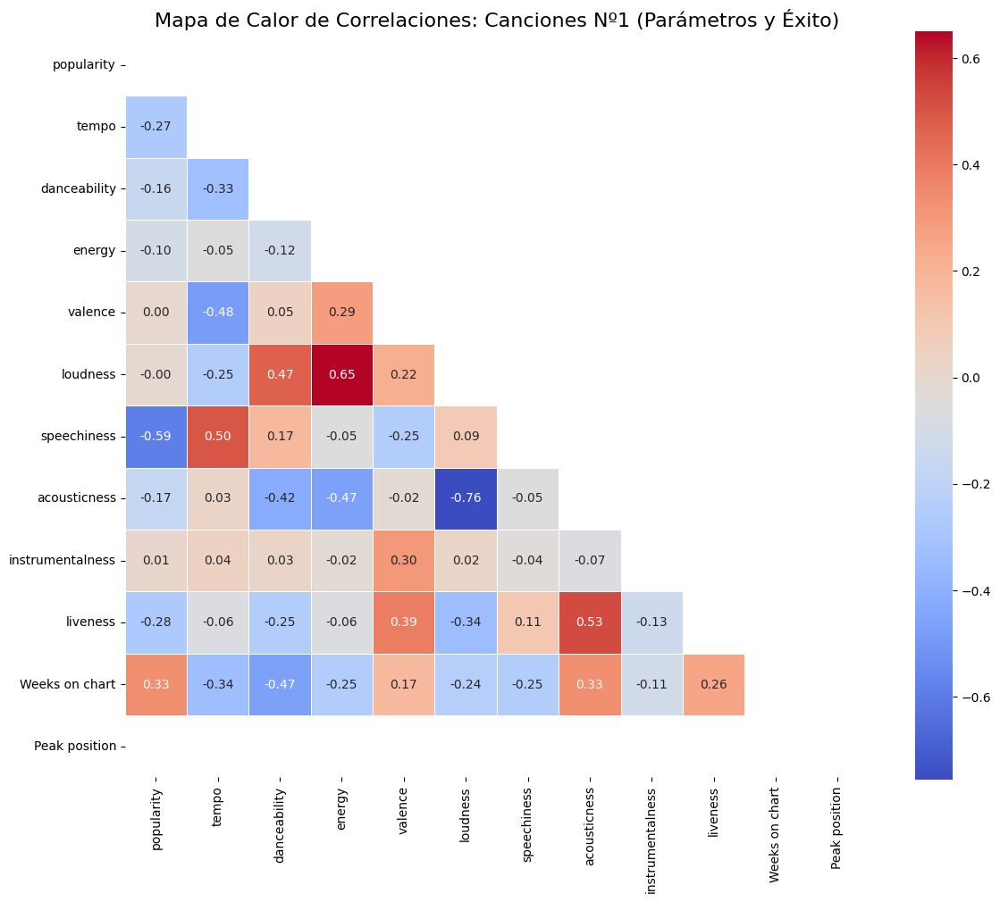

In [56]:
parametros_canciones = [
    'popularity', 'tempo', 'danceability', 'energy', 'valence', 
    'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness'
]

parametros_exito = ['Weeks on chart', 'Peak position']

# Se filtran por las canciones que solo estuvieron en el puesto Nº1 alguna vez
canciones_n1 = df_merged[df_merged["Pos. this week"] == 1]

# DataFrame con las columnas relevantes para estas canciones
df_corr_n1 = canciones_n1[parametros_canciones + parametros_exito].dropna()

# Calcular la matriz de correlación
correlation_matrix_n1 = df_corr_n1.corr()

# Máscara para mostrar solo la matriz inferior
import numpy as np
mask = np.triu(np.ones_like(correlation_matrix_n1, dtype=bool))

# Mapa de calor
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))
sns.heatmap(
    correlation_matrix_n1, mask=mask, cmap="coolwarm", annot=True, fmt=".2f", 
    cbar=True, square=True, linewidths=.5
)
plt.title("Mapa de Calor de Correlaciones: Canciones Nº1 (Parámetros y Éxito)", fontsize=16)
plt.tight_layout()
plt.show()

Aquí realizamos la correlación entre parámetros musicales y métricas de éxito sobre las canciones que fueron Nº1 para descubrir que patrones fueron clave para que alcanzaran esa posición.
Cada celda en el gráfico representa el grado de relación entre dos variables, en cuanto a los colores el rojo intenso representa una correlación positiva fuerte (cercana a 1), por el contrario, el azul intenso indica una correlación negativa fuerte (cercana a -1), y por último, el blanco o tonos neutros: muestran una correlación débil o inexistente (cercana a 0).

#### Gráficos de dispersión

##### Bailabilidad vs popularidad

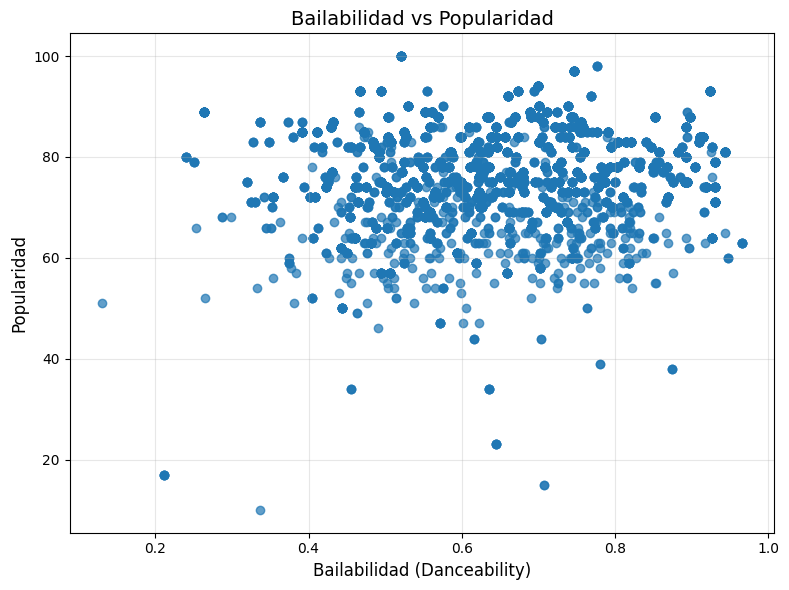

In [57]:
plt.figure(figsize=(8, 6))
plt.scatter(df_merged['danceability'], df_merged['popularity'], alpha=0.7)
plt.title("Bailabilidad vs Popularidad", fontsize=14)
plt.xlabel("Bailabilidad (Danceability)", fontsize=12)
plt.ylabel("Popularidad", fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Este gráfico de dispersión muestra la relación entre la bailabilidad y la popularidad de canciones. Aunque no hay una correlación clara o fuerte, se observa que muchas canciones con bailabilidad media a alta (0.4 - 0.8) tienden a tener popularidad alta (60 - 80). Esto sugiere que la bailabilidad puede influir en la popularidad, pero no es el único factor determinante.

#### Canciones con más semanas en el Nº1

Para extraer las canciones que se han mantenido durante más semanas en el Nº1, vamos a filtrar las que han estado, al menos, una semana en esta posición ("Pos. this week").

In [59]:
canciones_n1 = df_billboard[df_billboard["Pos. this week"] == 1] # Canciones en el Nº1 cada semana

Vamos a calcular, también, el número de semanas que estas canciones se han mantenido en el Nº1. Lo haremos mediante un *.groupby* para quedarnos únicamente con los datos que nos interesan para dibujar nuestro gráfico de barras.

In [60]:
# Calculamos el número de semanas que se han mantenido en el Nº1
weeks_n1 = (canciones_n1.groupby(["Title","Artist"], as_index= False).agg({"Weeks on chart" : "max",
                                                                           "Date" : lambda x: len(x)})).rename(columns= {"Date" : "Weeks N1"})

Una vez obtenida esta información, podemos dibujar nuestro gráfico para representar la información.

In [61]:
fig1 = px.bar(data_frame = weeks_n1,
       x          = "Title",
       y          = "Weeks N1",
       hover_data = "Artist",
       color      = "Weeks on chart",
       title= "Canciones con más semanas en el Nº1",
       labels= {
           "Title" : "Canción",
           "Artist" : "Artista",
           "Weeks N1" : "Semanas en el Nº1",
           "Weeks on chart" : "Semanas en el top 100"
       },
       color_continuous_scale= "Purpor"
      )

fig1.update_layout(
    xaxis_title="Canciones",  # Etiqueta del eje X
    yaxis_title="Semanas en el Nº1",  # Etiqueta del eje Y
    title_font_size=20,  # Tamaño del título
    title_x=0.5,  # Centrar el título
    coloraxis_colorbar=dict(
        title="Semanas Totales"  # Título de la barra de color
    )
)

fig1.show()

Son 18 las canciones que han estado, al menos, una semana en el Nº1 de la lista **Billboard**.  

La canción que más semanas se ha mantenido en el Nº1 ha sido **A Bar Song (Tipsy)**, del artista *Shaboozey* con 31 semanas en esta lista, de las cuales 18 han sido en el Nº1. Seguida de **Lovin on me** de *Jack Harlow* con 14 semanas en la lista, de las cuales 6 ha sido Nº1. También encontramos la canción **I Had Some Help** de los artistas *Post Malone y Morgan Wallen* que se ha mantenido 7 semanas en la lista **Billboard** con 6 en el Nº1. 

#### Canciones que más semanas se han mantenido en la lista del top 100

Para obtener las canciones que más semanas se han mantenido en esta lista vamos a hacer otro *.groupby* para quedarnos con el máximo de la columna "Weeks on chart" que nos indica las semanas que se ha mantenido en la lista Billboard 100 desde que ha entrado en esta lista, las semanas en el número 1 y la posición máxima de estas canciones en la lista. Ordenaremos este nuevo DataFrame de mayor a menor en función de la columna "Weeks on chart" (semanas en la lista). Una vez ordenado el DataFrame, nos podemos quedar con las primeras 15 filas que son las 15 canciones que más semanas se han mantenido en la lista y serán las que representemos en el gráfico de barras.

In [62]:
weeks_top = (df_billboard.groupby(["Title","Artist"], as_index= False).agg({"Weeks on chart" : "max",
                                                                           "Date" : lambda x: len(x),
                                                                           "Peak position" : "max"})).rename(columns= {"Date" : "Weeks N1"}).sort_values(by = "Weeks on chart", ascending= False)

weeks_top15 = weeks_top.head(15)

In [63]:
fig2 = px.bar(
    data_frame=weeks_top15,
    x="Weeks on chart",
    y="Title",
    hover_data=["Artist", "Weeks N1"],
    color="Weeks on chart",
    title="15 Canciones con más semanas en el Top 100",
    labels= {
           "Title" : "Canción",
           "Artist" : "Artista",
           "Weeks N1" : "Semanas en el Nº1",
           "Weeks on chart" : "Semanas en el top 100"
       },
    color_continuous_scale="Purpor"
)

fig2.update_layout(
    xaxis_title="Semanas en el Top 100",
    yaxis_title="Título de la Canción",
    title_x=0.5,  # Centrar el título
    yaxis=dict(autorange="reversed"),  # Invertir el orden de las canciones
    hoverlabel=dict(font_size=12)
)

fig2.show()

La canción que más semanas se ha mantenido en esta lista ha sido **Snooze** del artista *SZA*, que se ha mantenido en la lista Billboard 100 durante 70 semanas desde que entró en esta lista. De esas 70 semanas, 22 ha estado en el Nº1.

La segunda canción que más semanas se ha mantenido en la lista ha sido **Loose Control** de *Teddy Swims*, que se ha mantenido en la lista durante 66 semanas, de las cuales, 53 ha sido en el Nº1. 

La tercera canción que más semanas ha estado en la lista Billboard 100 ha sido **All I Want For Christmas Is You** de *Mariah Carey*, que se ha mantenido en la lista 65 semanas, de las cuales, 7 ha estado en el Nº1. Como curiosidad, siguiendo a esta canción navideña, tenemos otras 2 canciones navideñas en el puesto 5º y 6º de esta selección de canciones con más semanas en la lista. Estas son **Rockin' Around The Christmas Tree** de *Brenda Lee* y **Jingle Bell Rock** de *Bobby Helms*. Éstas se han mantenido 58 y 56 semanas en la lista, de las cuales, 6 y 7 han estado en el Nº1, respectivamente.

#### Gráfico de radar

Nos interesa evaluar qué hace a una canción entrar en el Nº1, estudiando algunos de sus parámetros como pueden ser el contenido hablado (*speechiness*), la "bailabilidad", el nivel de acústica o la energía que tienen las canciones que están en el Nº1. Estos parámetros están en las mismas unidades (un índice entre 0 y 1), por lo que será fácil compararlos.  
Para comparar estos parámetros podemos utilizar un gráfico de radar con estos parámetros representados para varias canciones. Para representarlo hemos escogido las 3 canciones que hemos visto anteriormente que más semanas han estado en el Nº1: **A Bar Song (Tipsy)**, **Lovin On Me** y **I Had Some Help**.

In [64]:
canciones = ['A Bar Song (Tipsy)', 'Lovin On Me', 'I Had Some Help']

parametros = ['speechiness', 'danceability', 'acousticness', 'energy']

canciones_seleccionadas = df_merged[df_merged['Title'].isin(canciones)].reset_index(drop=True)

Para dibujar un gráfico de radar debemos reorganizar los datos para que sean más fáciles de visualizar y representar en este gráfico. Eso lo hacemos con el método *melt* que transforma nuesto DataFrame a *long format*, transformando algunas columnas (en nuestro caso, los parámetros de las canciones) en filas. En este caso nos quedaremos con un DataFrame con 3 columnas: título de la canción, nombre del parámetro y el valor del mismo.

In [65]:
datos_melt = canciones_seleccionadas.melt(
    id_vars=['Title'],
    value_vars=parametros,
    var_name='Parámetro',
    value_name='Valor'
)


In [66]:
# Crear el gráfico de radar
fig3 = px.line_polar(
    datos_melt,
    r='Valor',
    theta='Parámetro',
    color='Title',
    line_close=True
)


fig3.update_traces(fill='toself')
fig3.update_layout(
    polar=dict(
        radialaxis=dict(
            visible=True,
            range=[0, 1]
        )
    ),
    showlegend=True,
    title='Comparación de Parámetros de Canciones'
)

fig3.show()


En este gráfico podemos ver que los parámetros que hemos estudiado para las 3 canciones más exitosas de este último año, son muy similares. Son canciones con una bailabilidad o una energía superiores al 0.6 y una acústica y un contenido hablado más cercano a 0.

#### Histogramas para los parámetros de las canciones

Vamos a realizar diferentes histogramas de algunos de los parámetros a estudiar de las canciones para saber la forma en la que se distribuyen entre las canciones que se encuentran en la lista Billboard 100.

##### Histograma de la popularidad

Vamos a realizar un histograma del parámetro **popularidad**. Para ello representamos en el eje X el índice de popularidad extraído de la API de Spotify (representado entre 0 y 100), y en el eje Y la frecuencia de este índice de popularidad.

In [67]:
fig4 = px.histogram(data_frame = df_merged, 
             x          = "popularity",
             color_discrete_sequence=["purple"])

fig4.update_layout(
    title="Histograma de Popularidad",
    title_x=0.5,
    xaxis_title="Popularidad",
    yaxis_title="Frecuencia"
)

fig4.show()

En el caso de la popularidad, vemos cómo la distribución está sesgada a la derecha, es decir, tenemos más valores de popularidad altos que pequeños. Vemos que la mayoría de las canciones se encuentran entre 60 y 90. Esto tiene sentido, teniendo en cuenta que hemos escogido canciones que han estado alguna vez en una lista con las canciones que más éxito están teniendo cada semana.

##### Histograma de la bailabilidad

Vamos a realizar un histograma del parámetro **bailabilidad**. Para ello representamos en el eje X el índice de bailabilidad extraído de la API de Spotify (representado entre 0 y 1), y en el eje Y la frecuencia de este índice de bailabilidad.

In [68]:
fig5 = px.histogram(data_frame = df_merged, 
             x          = "danceability",
             color_discrete_sequence=["purple"])

fig5.update_layout(
    title="Histograma de Bailabilidad",
    title_x=0.5,
    xaxis_title="Bailabilidad",
    yaxis_title="Frecuencia"
)

fig5.show()

En el caso de la bailabilidad, no vemos tan claro el sesgo como se veía en el caso de la popularidad, pero sí que es verdad que se ve un poco sesgada hacia la derecha, es decir, tenemos más valores de bailabilidad altos que pequeños. Vemos que la mayoría de las canciones tienen un índice de bailabilidad superior a 0.4. Si nos acordamos del gráfico de radar en el que estudiamos las "claves del éxito" de las canciones con más semanas en el Nº1, tenían una bailabilidad cercana a 1.

##### Histograma de la energía

Vamos a realizar un histograma del parámetro **energía**. Para ello representamos en el eje X el índice de bailabilidad extraído de la API de Spotify (representado entre 0 y 1), y en el eje Y la frecuencia de este índice de energía.

In [69]:
fig6 = px.histogram(data_frame = df_merged, 
             x          = "energy",
             color_discrete_sequence=["purple"])

fig6.update_layout(
    title="Histograma de Energía",
    title_x=0.5,
    xaxis_title="Energía",
    yaxis_title="Frecuencia"
)

fig6.show()

En el caso de la energía, tampoco se ve tan claro el sesgo como se veía en el caso de la popularidad, pero sí que es verdad que se ve un poco sesgada hacia la derecha, es decir, tenemos más valores de energía altos que pequeños. Vemos que la mayoría de las canciones tienen un índice de energía superior a 0.4 o, incluso, a 0.5. Si nos acordamos del gráfico de radar en el que estudiamos las "claves del éxito" de las canciones con más semanas en el Nº1, tenían una energía también cercana a 1.

##### Histograma del tempo

Vamos a realizar un histograma del parámetro **tempo**. Para ello representamos en el eje X el **tempo** en *beats por minuto*, extraído de la API de Spotify, y en el eje Y la frecuencia del **tempo** de las canciones.

In [70]:
fig7 = px.histogram(data_frame = df_merged, 
             x          = "tempo",
             color_discrete_sequence=["purple"])

fig7.update_layout(
    title="Histograma de Tempo",
    title_x=0.5,
    xaxis_title="Tempo en BPM",
    yaxis_title="Frecuencia"
)

fig7.show()

En el caso del tempo, la gráfica es más simétrica que en el resto de parámetros. Vemos que las canciones tienen un tempo entre 60 y 200 beats por minuto y que la mayoría de las canciones tienen un tempo entre 80 y 140 beats por minuto.

### Evolución temporal de las canciones más escuchadas

#### Evolución de las canciones que más tiempo han estado en lista
Con gráficos de líneas, vamos a comprobar cómo han evolucionado las canciones que más tiempo han estado en lista.

In [71]:
df_peak = df_merged.groupby(['Title', 'Artist'], as_index=False).agg({'Weeks on chart': 'max'}).rename(columns={'Weeks on chart': 'Max Weeks on Chart'}).sort_values(by='Max Weeks on Chart', ascending=False).reset_index(drop=True)
df_peak_list = df_peak["Title"][0:10].tolist()
df_top10 = df_merged[df_merged['Title'].isin(df_peak_list)]
df_top10['Song (Artist)'] = df_top10['Title'] + " (" + df_top10['Artist'] + ")"

C:\Users\claud\AppData\Local\Temp\ipykernel_9648\3858113119.py:4: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [72]:
fig = px.line(data_frame = df_top10,
       x          = "Date",
       y          = "Pos. this week",
       hover_data = ['Title', 'Artist','Weeks on chart', 'release_date'],
       color      = 'Song (Artist)',
       title='Evolución de las posiciones en la lista de las canciones que más se han mantenido en lista'
      )

fig.update_layout(
    yaxis=dict(
        autorange="reversed",  # Revertir el eje y
        title="Posición en la lista"),
        xaxis=dict(title='Fecha'),
        title_x=0.5,  
        title_y=0.95,
        legend_title_text='Canción (Artista)')

fig.show()

Lo primero que se observa es que a partir de mayo hay claramente un cambio de tendencia, ya que las canciones que más han resistido en lista desaparecen excepto **Lose Control** de Teddy Swims. Además, parece que puede haber cambios estacionales: viendo más de cerca la época navideña sale a la luz este cambio.

#### Canciones más populares en Navidad
Cogeremos las canciones que más se mantienen en lista desde la última semana de noviembre hasta la primera del año 2024.

In [15]:
christmas_dates = dates[1:8]
df_christmas = df_merged[df_merged['Date'].isin(christmas_dates)]
df_top10_ch = df_christmas[df_christmas['Pos. this week'] < 11]
df_top10_ch['Song (Artist)'] =  df_top10_ch.loc[:,('Title')] + " (" + df_top10_ch.loc[:,('Artist')] + ")"  

C:\Users\armej\AppData\Local\Temp\ipykernel_21364\2315891544.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_top10_ch['Song (Artist)'] =  df_top10_ch.loc[:,('Title')] + " (" + df_top10_ch.loc[:,('Artist')] + ")"


In [16]:
fig = px.line(data_frame = df_top10_ch,
       x          = "Date",
       y          = "Pos. this week",
       hover_data = ['Title', 'Artist','Weeks on chart', 'release_date'],
       color      = 'Song (Artist)',
       title='Posiciones durante la Navidad'
      )

fig.update_layout(
    yaxis=dict(
        autorange="reversed",  # Reverse the order of the y-axis
        title="Posición en la lista"),
        xaxis=dict(title='Fecha'),
        title_x=0.5,  
        title_y=0.95,
        legend_title_text='Canción (Artista)')
fig.show()

Aquí observamos que los grandes artistas dejan paso a la música navideña. *Mariah Carey* y *Brenda Lee* comienzan a aparecer ya en la última semana de noviembre, alternándose en la primera y segunda posición de la lista durante todas las navidades. En las siguientes posiciones, hay otras canciones propias de esta época. Curiosamente, se mantienen **muy estables**, por lo que claramente hay un mercado musical importante para esta época.

#### Panorama musical a partir de mayo 2024
Ahora, nos movemos hacia mayo de 2024 para ver exactamente qué ocurre. Cogeremos las que más semanas están en lista durante esta época, desde mayo hasta hoy.

In [17]:
dates_24 = dates[24:]
df_2024 = df_merged[df_merged['Date'].isin(dates_24)]
df_top10_24 = df_2024[df_2024['Pos. this week'] < 11]
df_top10_24['Song (Artist)'] = df_top10_24['Title'] + " (" + df_top10_24['Artist'] + ")"

C:\Users\armej\AppData\Local\Temp\ipykernel_21364\3253014253.py:4: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [18]:
fig = px.line(data_frame = df_top10_24,
       x          = "Date",
       y          = "Pos. this week",
       hover_data = ['Title', 'Artist','Weeks on chart', 'release_date'],
       color      = 'Song (Artist)',
       title='Posiciones a partir de mayo'
      )

fig.update_layout(
    yaxis=dict(
        autorange="reversed",  # Reverse the order of the y-axis
        title="Posición en la lista"),
        xaxis=dict(title='Fecha'),
        title_x=0.5,  
        title_y=0.95,
        legend_title_text='Canción (Artista)')

fig.show()

Aquí las cosas cambian radicalmente. Al principio de la gráfica, vemos que aparecen nuevos lanzamientos importantes, como **A Bar Song** de *Shaboozey*, **Beautiful Things** de *Benson Boone* o **I Had Some Help** de *Post Malone*. Al aparecer un buen número de nuevos éxitos, las descargas y reproducciones de estas canciones provocan un cambio en el panorama musical actual. 

Además, vemos que la gráfica es mucho más irregular que en Navidad. Las grandes fluctuaciones pueden deberse precisamente a todos los nuevos éxitos que aparecen alrededor de mayo de 2024.

#### Canciones más populares en Spotify y sus posiciones en la lista
Podemos ahora contrastar las canciones más populares actualmente en Spotify con los datos de la lista Billboard. Para ello, cogeremos los datos de las canciones con 90 o más de popularidad.

In [77]:
df_popularity = df_merged[df_merged['popularity'] >= 90]
df_popularity['Song (Artist)'] = df_popularity['Title'] + " (" + df_popularity['Artist'] + ")"

C:\Users\claud\AppData\Local\Temp\ipykernel_9648\352713453.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [78]:
fig = px.line(data_frame = df_popularity,
       x          = "Date",
       y          = "Pos. this week",
       hover_data = ['Title', 'Artist','Weeks on chart', 'release_date'],
       color      = 'Song (Artist)',
       title='Evolución de las canciones más populares en Spotify'
      )

fig.update_layout(
    yaxis=dict(
        autorange="reversed",  # Reverse the order of the y-axis
        title="Posición en la lista"),
        xaxis=dict(title='Fecha'),
        title_x=0.5,  # Center the title
        title_y=0.95,
        legend_title_text='Canción (Artista)')

fig.show()

Aquí vemos que estas aparecen en la lista, e incluso varias en las posiciones más altas, como **Die With A Smile** de *Lady Gaga y Bruno Mars* o **Birds Of A Feather** de *Billie Eillish*.

### Análisis por géneros

#### Los géneros más habituales en la lista por mes
Podemos comenzar analizando los géneros musicales con más presencia en la lista cada mes.

In [79]:
df_monthly = df_merged[['Title', 'Date', 'main_genre']]
year_month  = [date[0:7] for date in df_monthly['Date']]
df_monthly['month'] = year_month
df_filtered = df_monthly[df_monthly['main_genre'] != ''].drop_duplicates(subset='Title')  # coger valores individuales de canciones
df_filtered = df_filtered.groupby(['month', 'main_genre'], as_index=False).count().sort_values(by=['month', 'Date'], ascending=False).reset_index(drop=True)
df_filtered['rank'] = df_filtered.groupby('month')['Date'].rank(method='first', ascending=False)
df_top5 = df_filtered[df_filtered['rank'] <= 5]

C:\Users\claud\AppData\Local\Temp\ipykernel_9648\1258136103.py:3: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [80]:
fig = px.bar(
    df_top5,
    x='month',
    y='Date',
    color='main_genre',
    text='Date',
    title="TOP 5 géneros más populares cada mes",
    labels={'Date': 'Número de canciones', 'month': 'Mes', 'main_genre': 'Género', 'rank': 'Pos. en el TOP 5'},
    hover_data={'main_genre': True, 'Date': True, 'rank': True},
    barmode='group',  # To display bars grouped by month
)

fig.update_layout(
    xaxis_title="Mes",
    yaxis_title="Número de canciones",
    legend_title="Género",
    title_x=0.5,  # Center the title
    hovermode='x unified',
    xaxis=dict(
        tickformat='%Y-%m',  # Format the x-axis ticks as Year-Month
        # type='category', 
        # autorange='reversed'    # Treat x-axis as categorical
    )
)

fig.show()

Aquí hay relativa variación respecto a los géneros mes a mes. En general, vemos que los más escuchados suelen ser **pop, hip hop de Atlanta** y **country contemporáneo**. 

Habría que analizar cada mes para tener una idea más clara, ya que es curioso cómo aparecen otros géneros y subgéneros a lo largo del año. Por ejemplo, el **country** tiene otros subgéneros como el *country moderno* o el *country de Oklahoma* que también se dejan ver por la lista. El **hip hop**, además del *Atl hip hop*, también tiene otros subgéneros como el *hip hop canadiense*.

Además, también pueden verse otros como **adult standards** en diciembre de 2023, al cual pertenecen canciones navideñas como **It's The Most Wonderful Time Of The Year** o **Let It Snow, Let It Snow, Let It Snow!**. Otro ejemplo es el género Halloween en noviembre de 2024.



#### Gráfico sunburst para géneros
Podemos crear también un gráfico sunburst para ver de forma visual los géneros que contienen más canciones en la lista. También podremos ver los artistas más presentes en el panorama musical.

In [81]:
df_genre = df_merged[df_merged['main_genre'] != '']
df_genre = df_genre[['Title', 'Artist', 'main_genre']].reset_index(drop=True)
unique_songs_df = df_genre.drop_duplicates(subset=['Title']).reset_index(drop=True).dropna()

In [82]:
fig = px.sunburst(
    unique_songs_df,
    path=['main_genre', 'Artist', 'Title'],  # Define the hierarchy
    title="Jerarquía musical: Género > Artista > Canción",
    
)

fig.update_layout(
    title={
        'text': "Jerarquía musical: Género > Artista > Canción",
        'y': 0.95,
        'x': 0.5,
        'xanchor': 'center',
        'yanchor': 'top'
    },
    margin=dict(t=40, l=10, r=10, b=10),
)

fig.show()

A primera vista, ya observamos que los géneros más escuchados son el **pop**, el **Alt. hip hop** y el **country contemporáneo**, como habíamos visto anteriormente.

Entrando un poco en los géneros:
+ **Pop**: la más escuchada es indudablemente *Taylor Swift*, quien cuenta con 46 canciones que han conseguido entrar a la lista en algún momento. También vemos a otras importantes artistas como *Beyoncé*, *Sabrina Carpenter*, *Ariana Grande* u *Olivia Rodrigo*, las cuales cuentan con varios títulos en la lista a lo largo del año.
+ **Atl. hip hop**: *Future & Metro Boomin* y *Future* son los artistas con más rpresencia.
+ **Country contemporáneo**: *Morgan Wallen+ y *Luke Combs*, aunque aquí hay una gran variedad de artistas con canciones en la lista.

Se puede ir desglosando más hasta encontrar otros artistas importantes, como *Billie Eillish* y *Lady Gaga* dentro del **Pop Art** o *Shaboozey* en **Country pop moderno**.

#### Pie plot

In [29]:
canciones_n1_api = df_merged[df_merged["Pos. this week"] == 1]

##### Distribución de Géneros Musicales

In [25]:
# Contar la cantidad de canciones por género
genre_counts = df_merged['main_genre'].value_counts()

# Filtrar para mostrar solo los géneros más comunes
top_genres = genre_counts[genre_counts > 100]  # Ajusta el umbral según sea necesario

# Crear gráfico de tarta
fig_pie = px.pie(top_genres, values=top_genres.values, names=top_genres.index,
                 title='Distribución de Géneros Musicales',
                 color_discrete_sequence=px.colors.qualitative.Plotly)  # Usar colores contrastantes
fig_pie.update_traces(textinfo='percent+label')  # Muestra porcentaje y etiqueta
fig_pie.update_layout(title_font_size=20)  # Aumentar tamaño del título
fig_pie.show()

##### Popularidad Media por Género

In [107]:
# Calcular la popularidad media por género
popularity_by_genre = canciones_n1_api.groupby('main_genre')['popularity'].mean().sort_values()

# Filtrar para mostrar solo los géneros más comunes
top_popularity_genres = popularity_by_genre[popularity_by_genre > 50]  # Ajusta el umbral según sea necesario

# Crear gráfico de tarta
fig_pie_popularity = px.pie(top_popularity_genres, values=top_popularity_genres.values, names=top_popularity_genres.index,
                             title='Popularidad Media por Género',
                             color_discrete_sequence=px.colors.qualitative.Plotly)  # Usar colores contrastantes
fig_pie_popularity.update_traces(textinfo='percent+label')  # Muestra porcentaje y etiqueta
fig_pie_popularity.update_layout(title_font_size=20)  # Aumentar tamaño del título
fig_pie_popularity.show()

#### Box plot

##### Boxplot de la Popularidad por Género Musical

C:\Users\armej\AppData\Local\Temp\ipykernel_21364\384268892.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




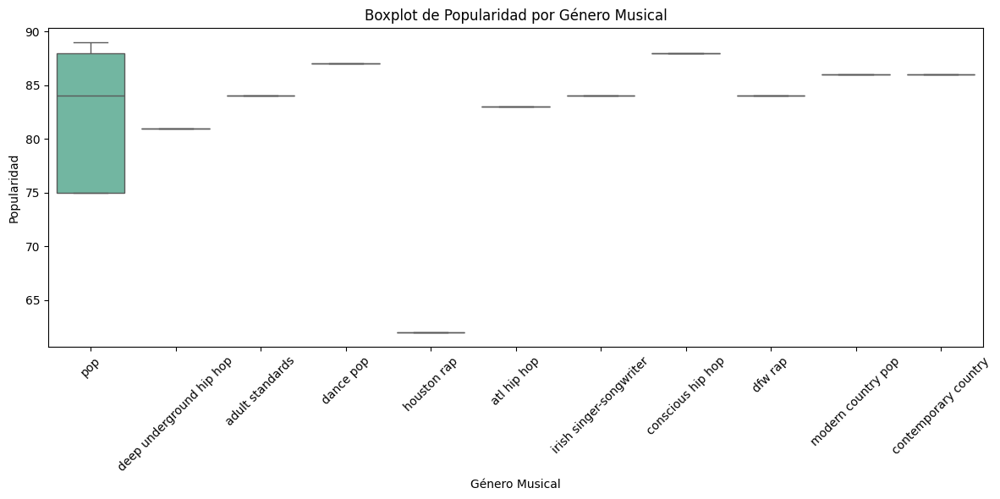

In [32]:
# Crear el boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(data=canciones_n1_api, x='main_genre', y='popularity', palette='Set2')
plt.title('Boxplot de Popularidad por Género Musical')
plt.xlabel('Género Musical')
plt.ylabel('Popularidad')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### Boxplot de la energía por género

C:\Users\claud\AppData\Local\Temp\ipykernel_9648\2182052385.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




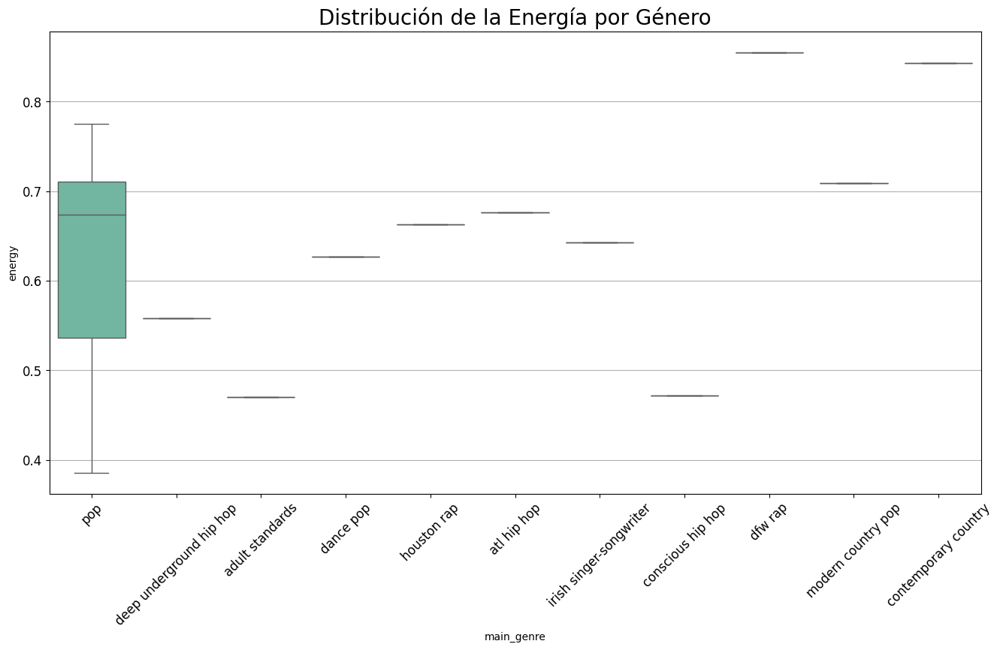

In [ ]:
plt.figure(figsize=(16, 8))  # Aumentar tamaño de la figura
sns.boxplot(data=canciones_n1_api, x='main_genre', y='energy', palette='Set2')  # Usar una paleta de colores
plt.title('Boxplot de la Energía por Género', fontsize=20)  # Aumentar tamaño del título
plt.xticks(rotation=45, fontsize=12)  # Rotar etiquetas y aumentar tamaño
plt.yticks(fontsize=12)  # Aumentar tamaño de las etiquetas del eje y
plt.grid(axis='y')  # Añadir líneas de cuadrícula para mejor visualización
plt.show()

### Contrastes de hipótesis

Hemos visto que las canciones que han estado en la lista Billboard 100 durante el último año pertenecen a géneros diferentes. Esto nos hace preguntarnos si existen diferencias entre la popularidad o algunos de los parámetros de las canciones en función del género que queramos estudiar. Esto lo podemos evaluar mediante **contrastes de hipótesis**. Realizaremos dos contrastes de hipótesis para saber si el género más escuchado que es el **pop** tiene la misma popularidad que los otros dos géneros más escuchados: **atl. hip hop** y **country contemporáneo**.

Primero, estudiaremos si la popularidad de las canciones de **pop** es igual a la de las canciones de **atl. hip hop** mediante el siguiente contraste:+

- $H_0$: la **popularidad** de las canciones de **pop** es de media **igual** que la popularidad de las canciones de **atl. hip hop**.
- $H_1$: la **popularidad** de las canciones de **pop** es **diferente** que la popularidad de las canciones de **atl. hip hop**.

Para este contraste de hipótesis necesitaremos evaluar, primero, si las distribuciones de las canciones de cada uno de los géneros son normales o no y también si las varianzas son iguales para saber qué test utilizar para el primer contraste. Es decir, realizaremos otros 2 contrastes de hipótesis:

**NORMALIDAD**
- $H_0$: las muestras siguen una **distribución normal**.
- $H_1$: **no** la siguen.

**IGUALDAD DE VARIANZAS**
- $H_0$: las muestras tienen varianzas **iguales**.
- $H_1$: las muestras tienen varianzas **diferentes**.


In [83]:
canciones_pop = df_merged[df_merged["main_genre"] == "pop"]

In [84]:
canciones_hip_hop = df_merged[df_merged["main_genre"] == "atl hip hop"]

##### Test de normalidad

In [85]:
from scipy import stats

alpha = 0.05 # nivel de significación

student = True # Asumimos que usaremos la t de Student

popularity_pop = canciones_pop["popularity"].dropna()
popularity_hip_hop = canciones_hip_hop["popularity"].dropna()

In [86]:
# Aplicaremos stats.normaltest() a ambas muestras y compararemos con alpha, con esto vamos a verificar si son distribuciones normales o no.

_, canciones_pop = stats.normaltest(popularity_pop)
_, canciones_rap = stats.normaltest(popularity_hip_hop)

if canciones_pop < alpha:
    print(f"canciones_pop no se ajusta a una distribución normal (p = {popularity_pop})")
    student = False
else:
    print(f"canciones_pop tiene una distribución normal (p = {popularity_pop})")
    
if canciones_rap < alpha:
    print(f"canciones_hip_hop no se ajusta a una distribución normal (p = {popularity_hip_hop})")
    student = False
else:
    print(f"canciones_hip_hop tiene una distribución normal (p = {popularity_hip_hop})")

canciones_pop no se ajusta a una distribución normal (p = 0       89.0
3       86.0
4       75.0
7       86.0
20      83.0
        ... 
5229    90.0
5240    83.0
5254    85.0
5263    88.0
5281    86.0
Name: popularity, Length: 823, dtype: float64)
canciones_hip_hop no se ajusta a una distribución normal (p = 17      82.0
27      60.0
124     82.0
131     60.0
189     51.0
        ... 
5191    73.0
5198    76.0
5282    76.0
5291    82.0
5295    73.0
Name: popularity, Length: 294, dtype: float64)


#### Test de varianzas

In [87]:
_, p_levene = stats.levene(popularity_pop, popularity_hip_hop)

if p_levene < alpha:
    print(f"Las varianzas no son homogeneas (p = {p_levene})")
    student = False
else:
    print(f"Las varianzas son homogeneas (p = {p_levene})")

Las varianzas no son homogeneas (p = 0.003820633682893148)


Hemos obtenido que la popularidad de las canciones tanto de pop como de hip hop no siguen una distribución normal y que las varianzas no son homogéneas, por lo que tendremos que realizar un test no paramétrico como la **U de Mann-Whitney**, al no cumplirse los supuestos de normalidad y homogeneidad de varianzas.

In [88]:
u, p = stats.mannwhitneyu(popularity_pop, popularity_hip_hop)
    
print(f"El valor U de Mann-Whitney es: {u}")
print(f"El valor p es: {p}") 

El valor U de Mann-Whitney es: 169765.5
El valor p es: 7.7160077971750105e-25


Con un p-valor inferior al valor de significación, rechazamos la hipótesis nula de que la popularidad media entre las canciones de pop y las canciones de atl. hip hop son iguales con una confianza del 95%. Por lo tanto, hay una diferencia estadísticamente significativa entre las dos muestras. Es decir, podemos encontrar diferencias entre la popularidad media entre las canciones de pop y las de alt hip hop.

Podemos realizar el mismo estudio, pero considerando el género de **contemporary country**, que es el tercer género más representado en la lista Billboard.

In [89]:
canciones_country = df_merged[df_merged["main_genre"] == "contemporary country"]

##### Test de normalidad

In [90]:
popularity_country = canciones_country["popularity"].dropna()

In [91]:
# Aplicaremos stats.normaltest() a ambas muestras y compararemos con alpha, con esto vamos a verificar si son distribuciones normales o no.

_, canciones_pop = stats.normaltest(popularity_pop)
_, canciones_country = stats.normaltest(popularity_country)

if canciones_pop < alpha:
    print(f"canciones_pop no se ajusta a una distribución normal (p = {popularity_pop})")
    student = False
else:
    print(f"canciones_pop tiene una distribución normal (p = {popularity_pop})")
    
if canciones_rap < alpha:
    print(f"canciones_country no se ajusta a una distribución normal (p = {popularity_country})")
    student = False
else:
    print(f"canciones_country tiene una distribución normal (p = {popularity_country})")

canciones_pop no se ajusta a una distribución normal (p = 0       89.0
3       86.0
4       75.0
7       86.0
20      83.0
        ... 
5229    90.0
5240    83.0
5254    85.0
5263    88.0
5281    86.0
Name: popularity, Length: 823, dtype: float64)
canciones_country no se ajusta a una distribución normal (p = 6       82.0
8       80.0
9       81.0
11      72.0
46      74.0
        ... 
5236    83.0
5238    82.0
5252    70.0
5269    75.0
5285    75.0
Name: popularity, Length: 542, dtype: float64)


#### Test de varianzas

In [92]:
_, p_levene = stats.levene(popularity_pop, popularity_country)

if p_levene < alpha:
    print(f"Las varianzas no son homogeneas (p = {p_levene})")
    student = False
else:
    print(f"Las varianzas son homogeneas (p = {p_levene})")

Las varianzas no son homogeneas (p = 0.027584134258074343)


Hemos obtenido que la popularidad de las canciones tanto de pop como de country contemporáneo no siguen una distribución normal y que las varianzas no son homogéneas, por lo que tendremos que realizar un test no paramétrico como la **U de Mann-Whitney**, al no cumplirse los supuestos de normalidad y homogeneidad de varianzas.

In [93]:
u, p = stats.mannwhitneyu(popularity_pop, popularity_country)
    
print(f"El valor U de Mann-Whitney es: {u}")
print(f"El valor p es: {p}") 

El valor U de Mann-Whitney es: 325344.5
El valor p es: 7.15944576776006e-47


Hemos obtenido un resultado muy similar al anterior contraste en el que comparábamos la popularidad del pop con la popularidad del hip hop. Con un p-valor inferior al valor de significación, rechazamos la hipótesis nula de que la popularidad media entre las canciones de pop y las canciones de country contemporáneo son iguales con una confianza del 95%. Por lo tanto, hay una diferencia estadísticamente significativa entre las dos muestras. Es decir, podemos encontrar diferencias entre la popularidad media entre las canciones de pop y las de country contemporáneo.

### Desafíos y resolución de problemas
Durante el desarrollo del proyecto, nos hemos encontrado con algunos problemas especialmente relacionados con la extracción y carga de datos:
+ **Baneo de la web de Billboard.** Al intentar parsear una gran cantidad de datos, la web nos bloqueaba constantemente. Para superarlo, hemos tenido que añadir headers a las requests con datos de distintos navegadores y la selección de la cookie de idioma, para hacerle creer que cada una de nuestras request masivas eran las de un usuario individual.
+ **Problemas con la API de Spotify**. Aquí posiblemente nos encontramos con la parte más dura, ya que el problema escapaba a nuestro control. Durante la extracción de datos, usamos la función *sp.artist* que tiene la API para extraer los datos de los géneros y seguidores que tienen los artistas. En un momento dado, esta función dejó de funcionar durante varios días, comprometiendo una buena parte de nuestro análisis. Esto nos ha hecho ser conscientes de que las API no siempre tienen un funcionamiento ideal . En cuanto volvió a funcionar, nos guardamos los datos en bruto inmediatamente a un csv para, al menos, solo tener que limpiarlos. Otro problema que hemos tenido a la hora de extraer los datos de la API es que los datos extraídos mediante Web Scraping de la lista Billboard son muy diferentes entre sí y también diferentes a los que tiene la API. En algunas ocasiones, las canciones con varios artistas vienen separados por *and*, *&* o *featuring*, pero no utilizan siempre este criterio. Esto nos ha llevado a tener algunos problemas a la hora de ampliar la información. Esto se ha solucionado intentando limpiar lo mejor posible los títulos de las canciones y los artistas para extraer el ID y buscar en la API de Spotify a través de este ID.
+ **Subida de datos a *Airtable*.** Para subir los datos, ha habido problemas debido a celdas con Nan. Tampoco tenía sentido transformarlas a None, ya que necesitaríamos que todas las columnas fueran de tipo object. Por tanto, al nos ser una gran cantidad de datos ni demasiado relevantes, los hemos obviado.

### Conclusiones
+ Se ha intentado estudiar si hay alguna correlación entre los parámetros musicales estudiados para averiguar si las canciones con más éxito siguen algún tipo de patrón. Sin embargo, vemos que la variedad musical, las tendencias y por tanto los gustos musicales de los oyentas son muy variados. Influye la época navideña, así como los nuevos lanzamientos, especialmente antes de verano.
+ El uso de las APIs, como en este caso la de Spotify, **puede resultar problemático**. Puede haber funcionalidades que dejen de estar operativas por causas ajenas a nuestro control, comprometiendo el estudio que se lleva a cabo. A pesar de la gran utilidad de las APIs, las cuales hacen más sencillo el proceso de extracción de datos, puede conllevar riesgos y dificultades. 
+ El webscraping, aunque es más tedioso, puede resultar más fiable. Aunque también puede tener riesgos y dificultades si las webs no autorizan la extracción masiva de datos.
+ Respecto a los géneros, nos hemos encontrado con una gran cantidad de subgéneros, lo cual ha dificultado la claificación de canciones. Sí se ha llegado a la conclusión de que los más escuchados son el **pop**, el **country contemporáneo** y el **Atlanta hip hop**.
+ Al realizar un proyecto como cietífico de datos, tener conocimiento sobre la materia que se estudia puede ser un gran complemento a favor de agilizar el trabjo. Sí que es cierto que en esta profesión se ha de contar con un perfil versátil para poder tratar una gran variedad de datos, incluso llegando a requerir formaciones específicas de cómo se emplean los datos para cada proyecto.

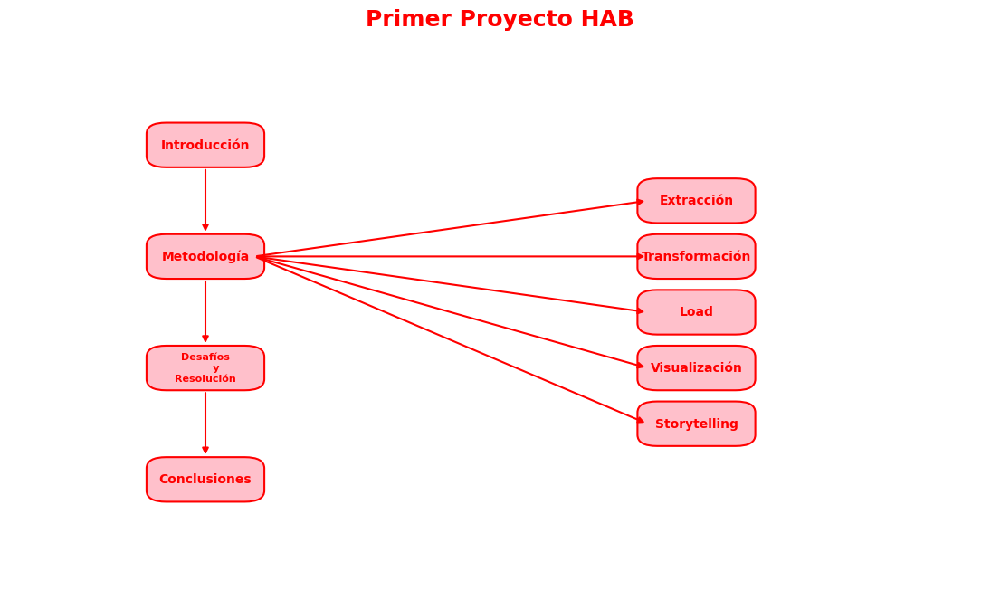